## Ejercicio 8

In [102]:
import numpy as np
import matplotlib.pyplot as plt
import scipy

In [103]:
X_fantoma = np.array([
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.8, 0.3, 0.3, 0.3, 0.0, 0.0],
    [0.0, 0.8, 0.8, 0.8, 0.3, 0.3, 0.3, 0.0],
    [0.0, 0.3, 0.8, 0.3, 0.3, 0.3, 0.3, 0.0],
    [0.0, 0.3, 0.3, 0.3, 0.3, 0.5, 0.3, 0.0],
    [0.0, 0.3, 0.3, 0.3, 0.5, 0.5, 0.5, 0.0],
    [0.0, 0.0, 0.3, 0.3, 0.3, 0.5, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
], dtype=float)

n = X_fantoma.shape[0]
x_fantoma = X_fantoma.reshape(-1)

In [104]:
def mascara_rayo(n, direccion, s):
    alfa = direccion[0]
    beta = direccion[1]
    matriz = np.zeros((n, n), dtype=int)
    for i in range(n):
        for j in range(n):
            if alfa * i + beta * j == s:
                matriz[i][j] = 1
    return matriz


def matriz_proyeccion(n, direcciones):
    filas_A = []
    rayos = []

    for direccion in direcciones:
        alfa = direccion[0]
        beta = direccion[1]
        valores_s = set()

        for i in range(n):
            for j in range(n):
                valores_s.add(alfa * i + beta * j)

        for s in sorted(valores_s):
            mascara = mascara_rayo(n, direccion, s)
            filas_A.append(mascara.reshape(-1))
            rayos.append((direccion, s))

    A = np.array(filas_A, dtype=float)
    return A, rayos

In [105]:
D2 = [(1, 0), (0, 1)]
D4 = D2 + [(1, 1), (1, -1)]
D7 = D4 + [(2, 1), (1, 2), (3, 1)]

A2, rayos2 = matriz_proyeccion(n, D2)
A4, rayos4 = matriz_proyeccion(n, D4)
A7, rayos7 = matriz_proyeccion(n, D7)

In [106]:
b7 = A7 @ x_fantoma
rng = np.random.default_rng(2026)
z = rng.standard_normal(b7.size)
escala = np.sqrt(np.mean(b7**2))

In [107]:
sigma = 0.06
b_sigma = b7 + sigma * escala * z

### Inciso a)

El costo $E(x)=\frac12\|A_7x-b_\sigma\|^2$ mide la discrepancia entre las mediciones
simuladas y las observadas. El factor $1/2$ simplifica la derivada.
El gradiente $A_7^T(A_7x-b_\sigma)$ indica la dirección de mayor aumento del costo.
La Hessiana $H=A_7^TA_7$ describe su curvatura y no depende de $x$.

Para cualquier $v$, se cumple $v^THv=\|A_7v\|^2$. Como `A7` tiene rango columna completo,
esta cantidad es positiva para $v\ne0$: $H$ es simétrica definida positiva.

In [108]:
def costo(x, A, b):
    residuo = A @ x - b
    return 0.5 * np.dot(residuo, residuo)

def gradiente(x, A, b):
    return A.T @ (A @ x - b)

H = A7.T @ A7
print("¿H es simétrica?", np.allclose(H, H.T))
print("Menor autovalor:", np.linalg.eigvalsh(H)[0])
assert np.allclose(H, H.T)
assert np.linalg.eigvalsh(H)[0] > 0

¿H es simétrica? True
Menor autovalor: 0.5132736028183065


### Inciso b)

In [109]:
def gradiente_descendiente(A, b, alpha, max_iter=10000, tol=1e-8):
    # Comenzamos con una imagen de ceros y preparamos los historiales.
    x = np.zeros(A.shape[1])
    costos = []
    normas_gradiente = []
    iteraciones = 0
    motivo = "máximo de iteraciones"

    for t in range(max_iter + 1):
        # Usamos las funciones del inciso a) para evaluar el costo y el gradiente.
        costo_actual = costo(x, A, b)
        grad = gradiente(x, A, b)
        norma_grad = np.linalg.norm(grad)

        costos.append(costo_actual)
        normas_gradiente.append(norma_grad)

        # Frenamos si el costo deja de ser finito o si el gradiente ya es pequeño.
        if not np.isfinite(costo_actual):
            motivo = "costo divergente"
            break
        if norma_grad <= tol:
            motivo = "tolerancia del gradiente"
            break
        if t == max_iter:
            break

        # Restamos alpha por el gradiente para obtener la nueva imagen.
        x = x - alpha * grad
        iteraciones += 1

    # Guardamos la solución y los datos necesarios para analizar las iteraciones.
    resultado = {"x": x, "costos": costos, "normas_gradiente": normas_gradiente,
                 "iteraciones": iteraciones, "motivo": motivo}
    return resultado

Tasa de aprendizaje: 0.027424756403856825
Iteraciones: 1446
Motivo de parada: tolerancia del gradiente
Costo final: 0.14153222462341683
Norma final del gradiente: 9.882126899159781e-11


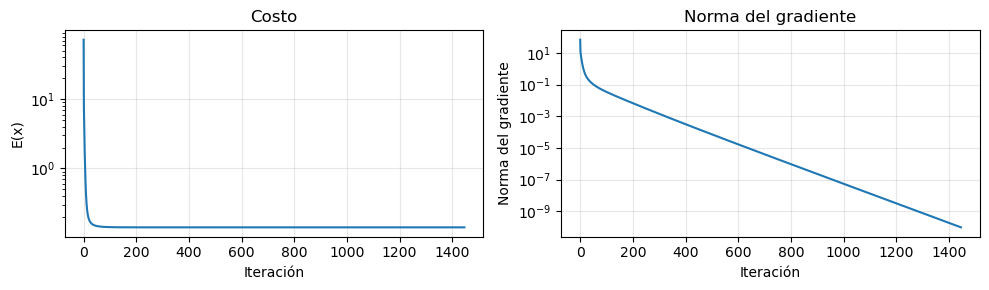

In [110]:
# Elegimos una tasa de aprendizaje a partir del mayor valor propio de H.
mu_max = np.linalg.eigvalsh(H)[-1]
alpha = 1.0 / mu_max

# Ejecutamos gradiente descendiente para las mediciones ruidosas de este ejercicio.
resultado_gd = gradiente_descendiente(A7, b_sigma, alpha, max_iter=10000, tol=1e-10)
x_gd = resultado_gd["x"]

print("Tasa de aprendizaje:", alpha)
print("Iteraciones:", resultado_gd["iteraciones"])
print("Motivo de parada:", resultado_gd["motivo"])
print("Costo final:", resultado_gd["costos"][-1])
print("Norma final del gradiente:", resultado_gd["normas_gradiente"][-1])

# Mostramos cómo cambian el costo y la norma del gradiente durante las iteraciones.
# semilogy usa una escala logarítmica vertical para distinguir los valores pequeños.
fig, axs = plt.subplots(1, 2, figsize=(10, 3))
axs[0].semilogy(resultado_gd["costos"])
axs[0].set_title("Costo")
axs[0].set_xlabel("Iteración")
axs[0].set_ylabel("E(x)")
axs[0].grid(alpha=0.3)

axs[1].semilogy(resultado_gd["normas_gradiente"])
axs[1].set_title("Norma del gradiente")
axs[1].set_xlabel("Iteración")
axs[1].set_ylabel("Norma del gradiente")
axs[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Inciso c)

Mayor valor propio de H: 36.46340500801557
Intervalo estable: 0 < alpha < 0.05484951280771365

Factor: 0.2 - Tasa de aprendizaje: 0.005484951280771365
La tasa está dentro del intervalo estable.
Costo inicial: 72.19013675874182 - Costo final: 0.1521318191654743
Iteraciones: 200

Factor: 1.0 - Tasa de aprendizaje: 0.027424756403856825
La tasa está dentro del intervalo estable.
Costo inicial: 72.19013675874182 - Costo final: 0.141571591610471
Iteraciones: 200

Factor: 1.8 - Tasa de aprendizaje: 0.04936456152694228
La tasa está dentro del intervalo estable.
Costo inicial: 72.19013675874182 - Costo final: 0.14153251060293323
Iteraciones: 200

Factor: 2.2 - Tasa de aprendizaje: 0.060334464088485015
La tasa está fuera del intervalo estable.
Costo inicial: 72.19013675874182 - Costo final: 2.718785642291037e+33
Iteraciones: 200



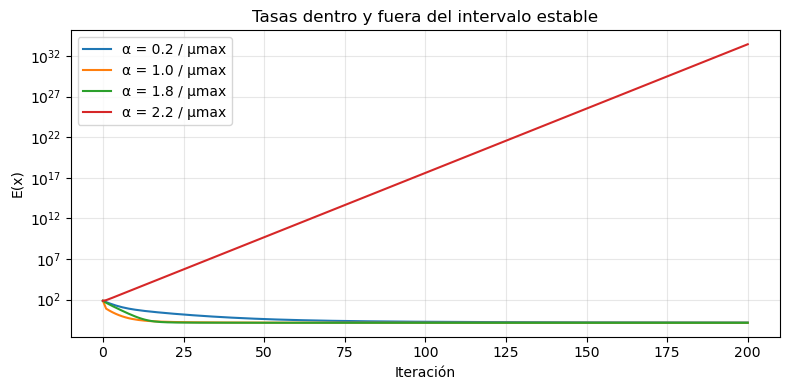

In [111]:
# Calculamos el mayor valor propio de H y el límite para una tasa estable.
valores_propios = np.linalg.eigvalsh(H)
mu_max = valores_propios[-1]
limite_alpha = 2 / mu_max

print("Mayor valor propio de H:", mu_max)
print("Intervalo estable: 0 < alpha <", limite_alpha)
print()

# Probamos tres tasas dentro del intervalo y una fuera.
factores = [0.2, 1.0, 1.8, 2.2]
fig, ax = plt.subplots(figsize=(8, 4))

for factor in factores:
    tasa = factor / mu_max

    # Cada llamada empieza con una imagen de ceros y permite hasta 200 iteraciones.
    resultado = gradiente_descendiente(A7, b_sigma, tasa, max_iter=200, tol=1e-10)
    costos_prueba = resultado["costos"]

    # Comparamos el costo inicial y final para ver cómo se comporta cada tasa.
    print("Factor:", factor, "- Tasa de aprendizaje:", tasa)
    if 0 < tasa < limite_alpha:
        print("La tasa está dentro del intervalo estable.")
    else:
        print("La tasa está fuera del intervalo estable.")
    print("Costo inicial:", costos_prueba[0], "- Costo final:", costos_prueba[-1])
    print("Iteraciones:", resultado["iteraciones"])
    print()

    # La escala logarítmica permite mostrar el descenso y el crecimiento del costo.
    etiqueta = "α = " + str(factor) + " / μmax"
    ax.semilogy(costos_prueba, label=etiqueta)

ax.set_xlabel("Iteración")
ax.set_ylabel("E(x)")
ax.set_title("Tasas dentro y fuera del intervalo estable")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Con los factores 0.2, 1.0 y 1.8, el costo disminuye y tiende a estabilizarse. Estas tasas están dentro del intervalo estable y el método se acerca a la solución. Con el factor 0.2 el descenso es más lento; con 1.0 y 1.8 se alcanzan costos menores en las 200 iteraciones probadas.

Con el factor 2.2, que está fuera del intervalo estable, el costo crece cada vez más en vez de estabilizarse. En este caso el método se vuelve inestable y diverge.

### Inciso d)

In [112]:
# Partimos de una imagen con todos sus píxeles en cero.
x0 = np.zeros(n**2)

# Calculamos el gradiente inicial y resolvemos H @ p0 
gradiente_inicial = gradiente(x0, A7, b_sigma)
p0 = np.linalg.solve(H, gradiente_inicial)

# Aplicamos una sola actualización del método de Newton.
x_newton = x0 - p0

# Comprobamos si el gradiente quedó cerca de cero.
gradiente_final = gradiente(x_newton, A7, b_sigma)
norma_gradiente_final = np.linalg.norm(gradiente_final)

print("Después de una iteración de Newton:")
print("Norma del gradiente:", norma_gradiente_final)

Después de una iteración de Newton:
Norma del gradiente: 1.685376233092072e-14


Después de una sola iteración de Newton, la norma del gradiente es aproximadamente $1{,}69 \times 10^{-14}$, es decir, prácticamente cero. Esto verifica que se alcanzó el mínimo.

Esto ocurre porque, para una función cuadrática con Hessiana constante, la aproximación que utiliza Newton coincide exactamente con la función. Por eso, el paso calculado lleva directamente al mínimo en una sola iteración.

### Inciso e)

Gradiente descendiente
Costo: 0.14153222462341683
Norma del gradiente: 9.882126899159781e-11
Error relativo: 0.11333490948795531

Newton
Costo: 0.14153222462341677
Norma del gradiente: 1.685376233092072e-14
Error relativo: 0.1133349095074178

lstsq
Costo: 0.14153222462341675
Norma del gradiente: 9.242410779200659e-14
Error relativo: 0.11333490950741712



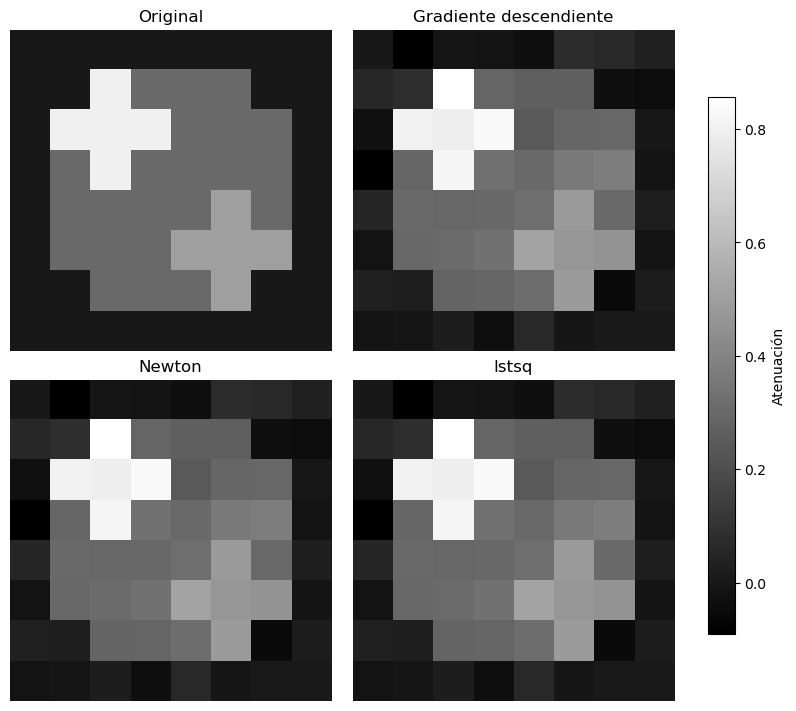

In [113]:
# Calculamos la solución de mínimos cuadrados para compararla con los otros métodos.
x_lstsq = np.linalg.lstsq(A7, b_sigma, rcond=None)[0]
nombres = ["Gradiente descendiente", "Newton", "lstsq"]
soluciones = [x_gd, x_newton, x_lstsq]

# Para cada método mostramos el costo, la norma del gradiente y el error respecto del fantoma.
for i in range(3):
    x = soluciones[i]
    error = np.linalg.norm(x - x_fantoma) / np.linalg.norm(x_fantoma)
    distancia = np.linalg.norm(x - x_lstsq)

    print(nombres[i])
    print("Costo:", costo(x, A7, b_sigma))
    print("Norma del gradiente:", np.linalg.norm(gradiente(x, A7, b_sigma)))
    print("Error relativo:", error)
    print()

# Preparamos las cuatro imágenes y usamos la misma escala de grises para compararlas.
imagenes = [X_fantoma, x_gd.reshape(n, n), x_newton.reshape(n, n), x_lstsq.reshape(n, n)]
titulos = ["Original", "Gradiente descendiente", "Newton", "lstsq"]
vmin = np.min(imagenes)
vmax = np.max(imagenes)

# Mostramos dos imágenes por fila y agregamos una barra de color común.
fig, axs = plt.subplots(2, 2, figsize=(8, 7), layout="constrained")
k = 0
for fila in range(2):
    for columna in range(2):
        axs[fila, columna].imshow(imagenes[k], cmap="gray", vmin=vmin, vmax=vmax)
        axs[fila, columna].set_title(titulos[k])
        axs[fila, columna].axis("off")
        k += 1

fig.colorbar(axs[0, 0].images[0], ax=axs, label="Atenuación", shrink=0.8)
plt.show()


Los tres métodos llegan a la misma reconstrucción dentro de sus tolerancias. El error
respecto del fantoma sigue siendo aproximadamente 0,113 porque las mediciones contienen ruido.
Newton y lstsq no eliminan ese ruido, resuelven el mismo problema que gradiente descendiente.
La diferencia está en el procedimiento y el costo de cálculo. Gradiente necesita una tasa
y varias iteraciones. Newton resuelve un sistema con la Hessiana en un paso y lstsq obtiene
directamente una solución de mínimos cuadrados, sin elegir una tasa de aprendizaje.